# P65: noise-source periods behind wrong answers
Regenerates every README figure from `data/` (run `analysis.py` first; the heavy step is `tools/audit/noise_secondary_peaks.py`).

In [1]:
import os, sys, json
import pandas as pd
from IPython.display import Image, display
HERE = os.path.abspath('.')
sys.path.insert(0, HERE)
import figures as F
os.makedirs(F.FIG, exist_ok=True)
pd.set_option('display.width', 200)
S = json.load(open('data/summary.json'))

## (b) The 22 `periodic_low_amplitude` stars in dev_medium_clean
Hand `_v9` and ranker v1 (p = 0.86 pick) with all 874 stars, without the 22, and on the 22 alone.

,mode,method,subset,n,success,wrong,alias,n_success,n_wrong,n_alias
0,fullyear,hand_v9,all 874,874,0.2700,0.0195,0.0080,236,17,7
1,fullyear,hand_v9,without the 22,852,0.2723,0.0176,0.0082,232,15,7
2,fullyear,hand_v9,only the 22,22,0.1818,0.0909,0.0000,4,2,0
3,fullyear,ranker_v1,all 874,874,0.3124,0.0160,0.0069,273,14,6
4,fullyear,ranker_v1,without the 22,852,0.3157,0.0106,0.0070,269,9,6
5,fullyear,ranker_v1,only the 22,22,0.1818,0.2273,0.0000,4,5,0
6,assigned,hand_v9,all 874,874,0.1545,0.0297,0.0046,135,26,4
7,assigned,hand_v9,without the 22,852,0.1573,0.0223,0.0047,134,19,4
8,assigned,hand_v9,only the 22,22,0.0455,0.3182,0.0000,1,7,0
9,assigned,ranker_v1,all 874,874,0.2014,0.0252,0.0023,176,22,2


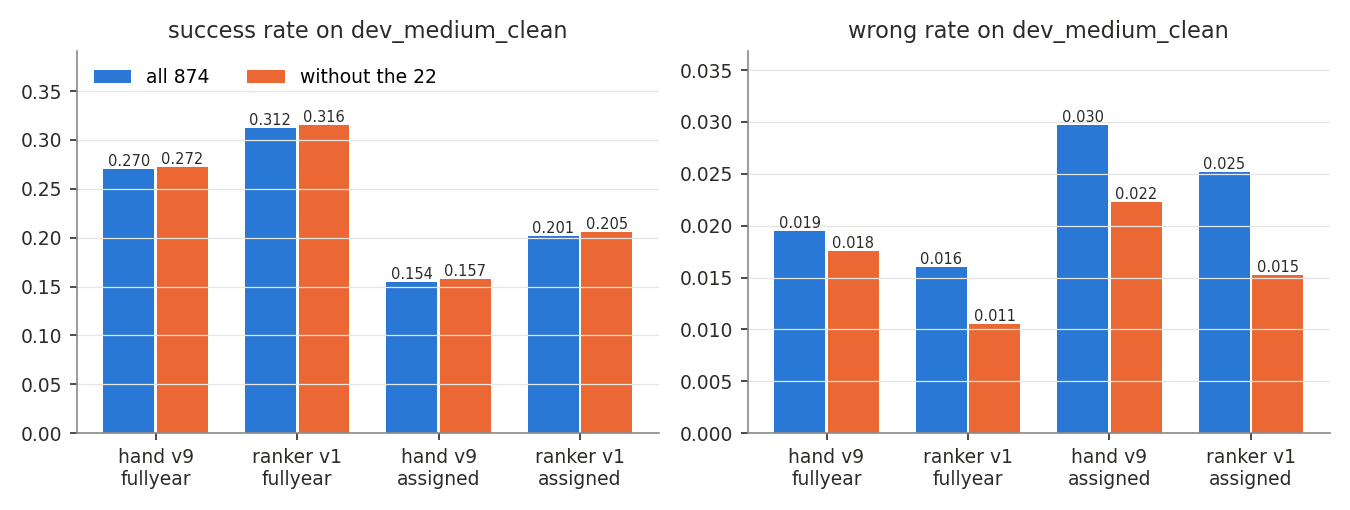

In [2]:
r = pd.read_csv('data/rates.csv'); display(r.round(4))
F.fig_rates(); display(Image('figures/rates_with_without_22.png'))

## (a) Wrong answers vs the noise stack's S/N at the reported period
Left: survival of the noise stack's min-half LS S/N at each answered-wrong top-1 period, against the same period in 50 random stacks. Right: why each wrong answer happened.

{'wrong_n': 64, 'wrong_why': {'no noise-period match': 23, 'coherent secondary noise signal': 21, 'coherent noise signal at P_ref': 13, 'P_ref, not coherent (red-noise peak)': 7}, 'wrong_why_by_class': {'misclassified_star': {'P_ref, not coherent (red-noise peak)': 0, 'coherent noise signal at P_ref': 1, 'coherent secondary noise signal': 0, 'no noise-period match': 0, 'All': 1}, 'periodic_low_amplitude': {'P_ref, not coherent (red-noise peak)': 1, 'coherent noise signal at P_ref': 11, 'coherent secondary noise signal': 0, 'no noise-period match': 2, 'All': 14}, 'quiet': {'P_ref, not coherent (red-noise peak)': 4, 'coherent noise signal at P_ref': 1, 'coherent secondary noise signal': 15, 'no noise-period match': 16, 'All': 36}, 'systematic_common_mode': {'P_ref, not coherent (red-noise peak)': 2, 'coherent noise signal at P_ref': 0, 'coherent secondary noise signal': 6, 'no noise-period match': 5, 'All': 13}, 'All': {'P_ref, not coherent (red-noise peak)': 7, 'coherent noise signal at

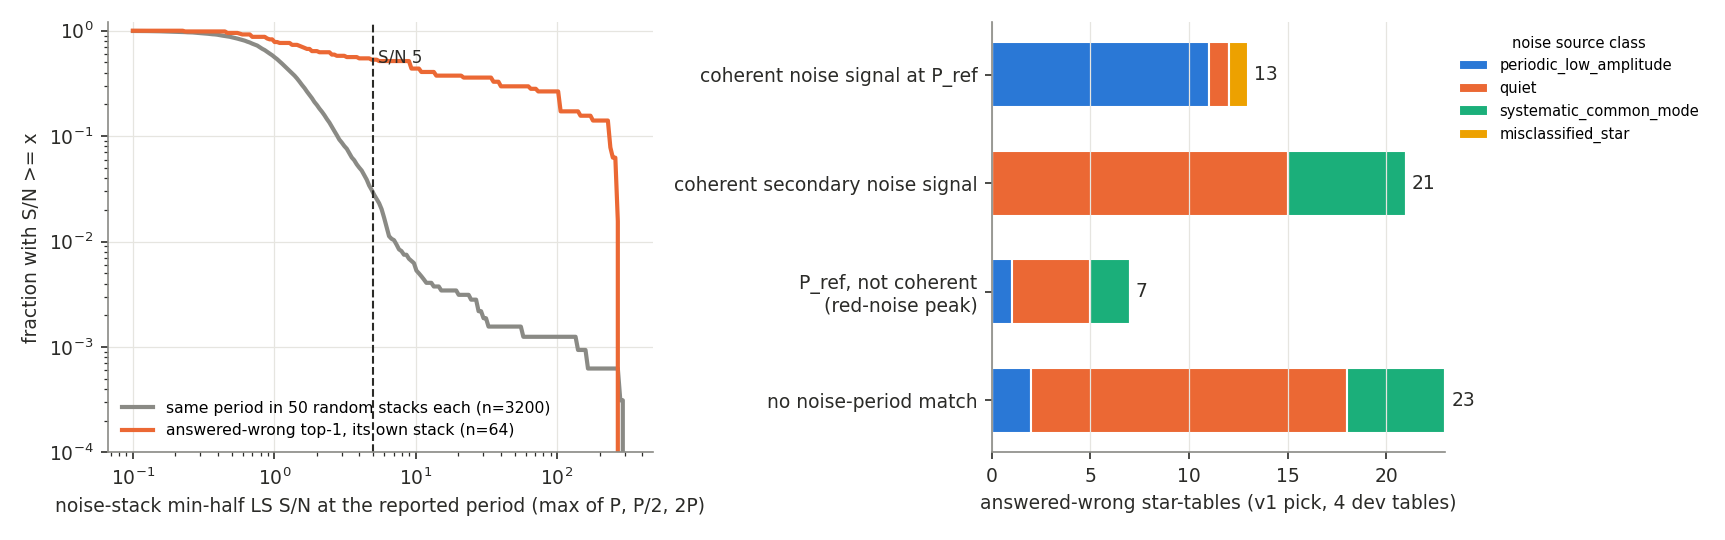

In [3]:
print({k: v for k, v in S.items() if k.startswith('wrong_')})
F.fig_wrong_snr(); display(Image('figures/wrong_vs_noise_snr.png'))

## The repeat offenders
Stack, full-year LS (P_ref blue, v1 wrong answers dashed orange), and a zoom on the wrong answers with each half-year's LS.

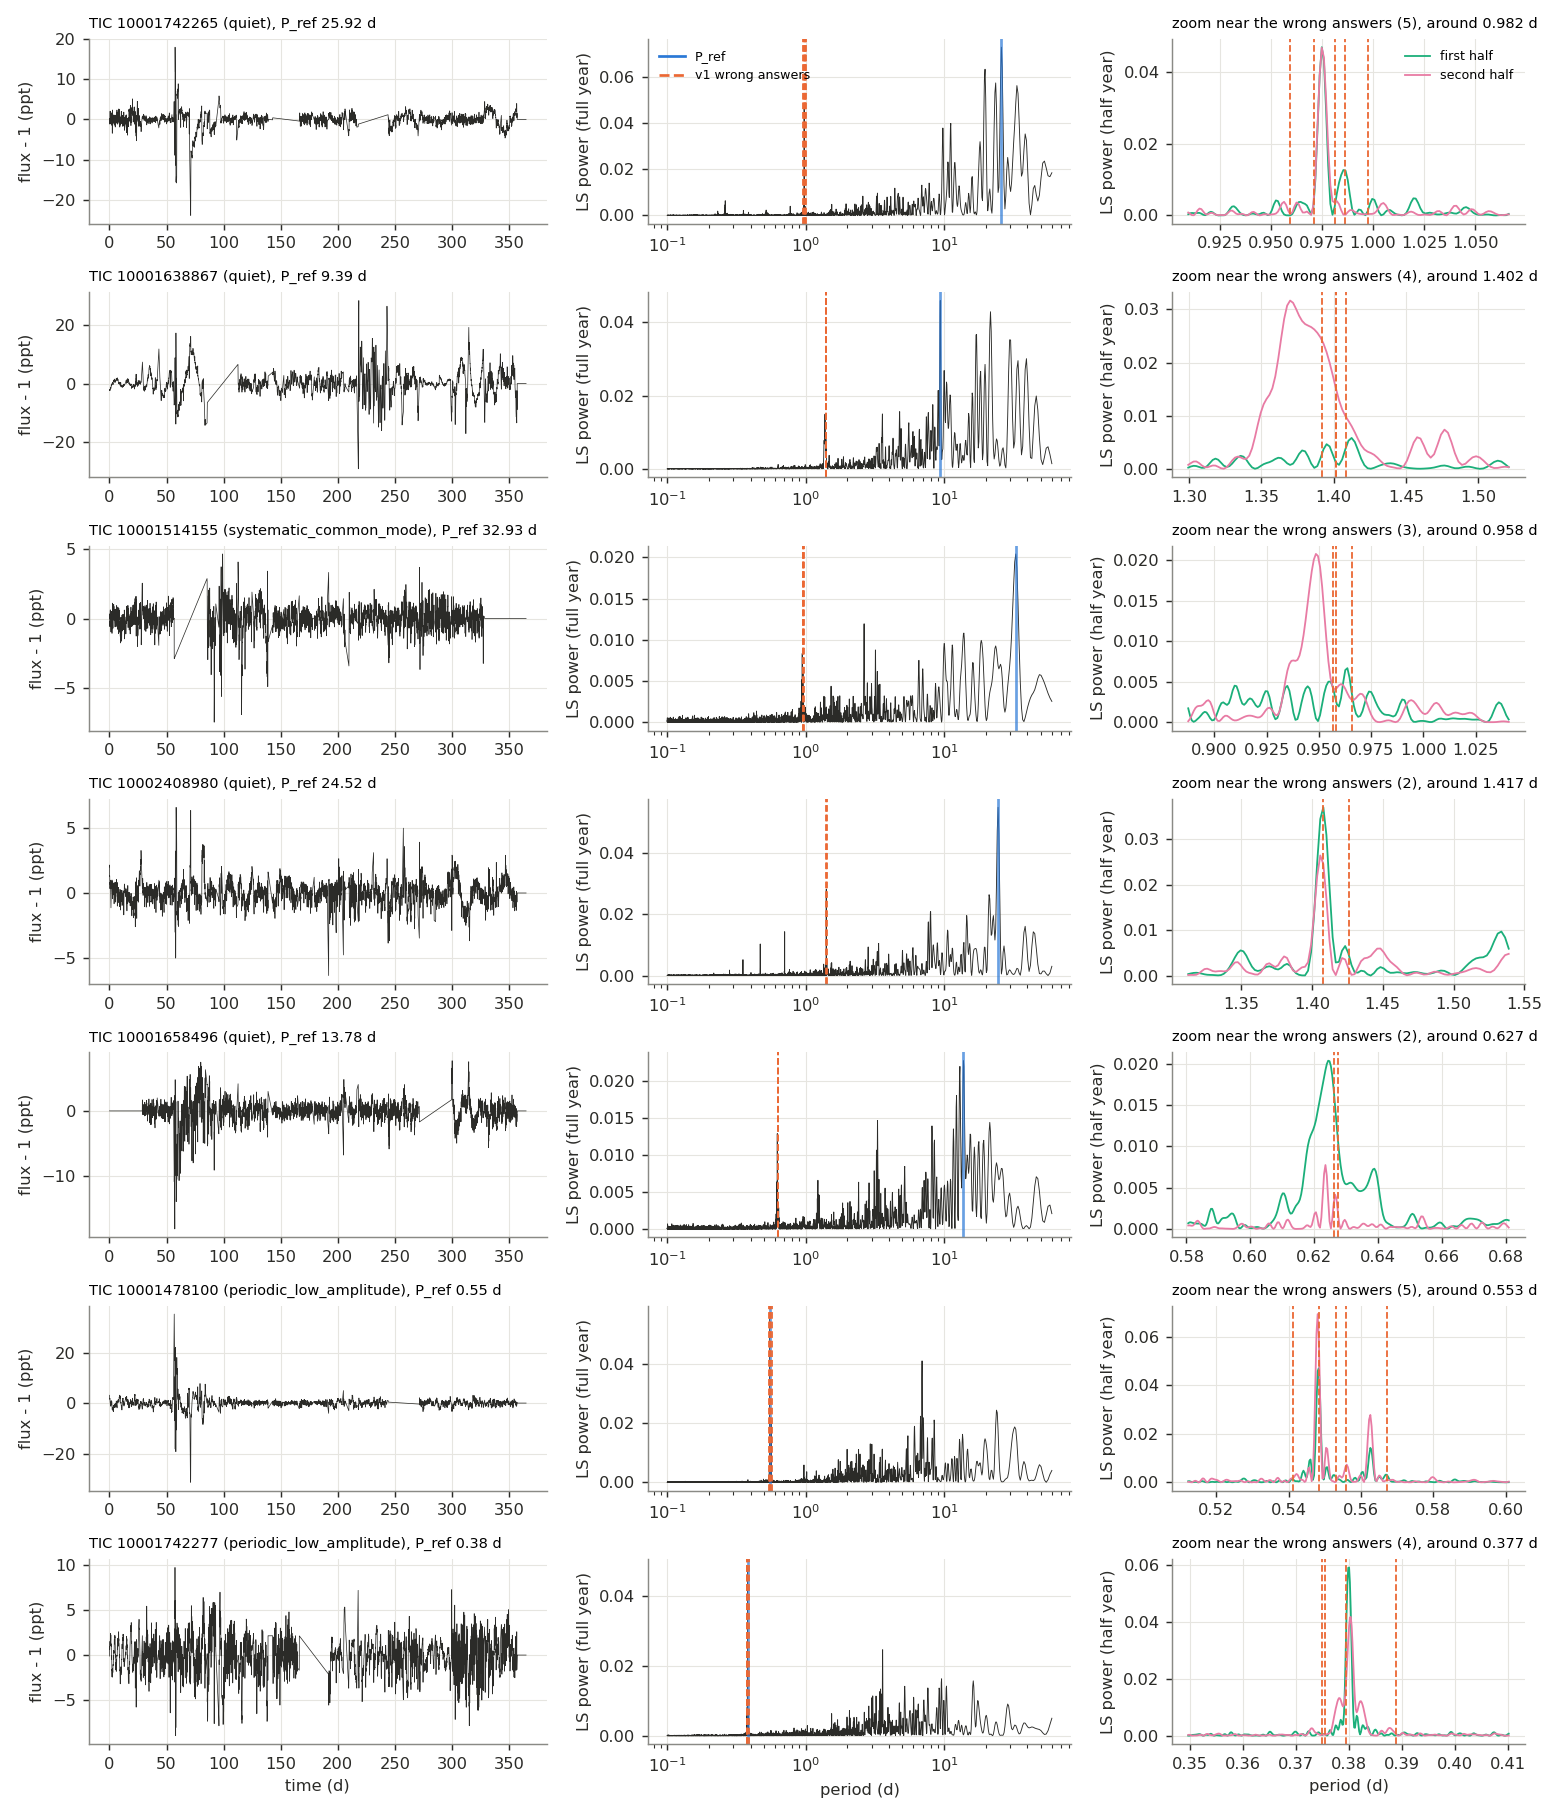

In [4]:
F.fig_offenders(None); display(Image('figures/offenders.png'))

## How common are secondary coherent signals?

,classification,n_sources,secondary_ge10,secondary_ge20,best_line_median_snr
0,contamination_candidate_crowded,63,25,14,11.357463
1,contamination_known_variable,90,57,49,65.334418
2,misclassified_star,1,1,1,182.425941
3,periodic_low_amplitude,34,18,10,79.627636
4,quiet,1044,104,53,5.960477
5,source_specific_unexplained,44,13,6,7.682573
6,systematic_common_mode,443,41,16,6.010053


{'10': {'sources': 143, 'files': 87363, 'files_by_pool': {'lt800k': 72608, 'ge800k': 14755}}, '20': {'sources': 69, 'files': 42141, 'files_by_pool': {'lt800k': 35211, 'ge800k': 6930}}, 'all_files_by_pool': {'lt800k': 800000, 'ge800k': 200000}, 'excluded_files_by_pool': {'lt800k': 106555, 'ge800k': 27828}, 'training_sets': {'train_v0': {'n': 3000, 'ge10': 349, 'ge20': 172}, 'negatives_v0': {'n': 4708, 'ge10': 460, 'ge20': 232}}}


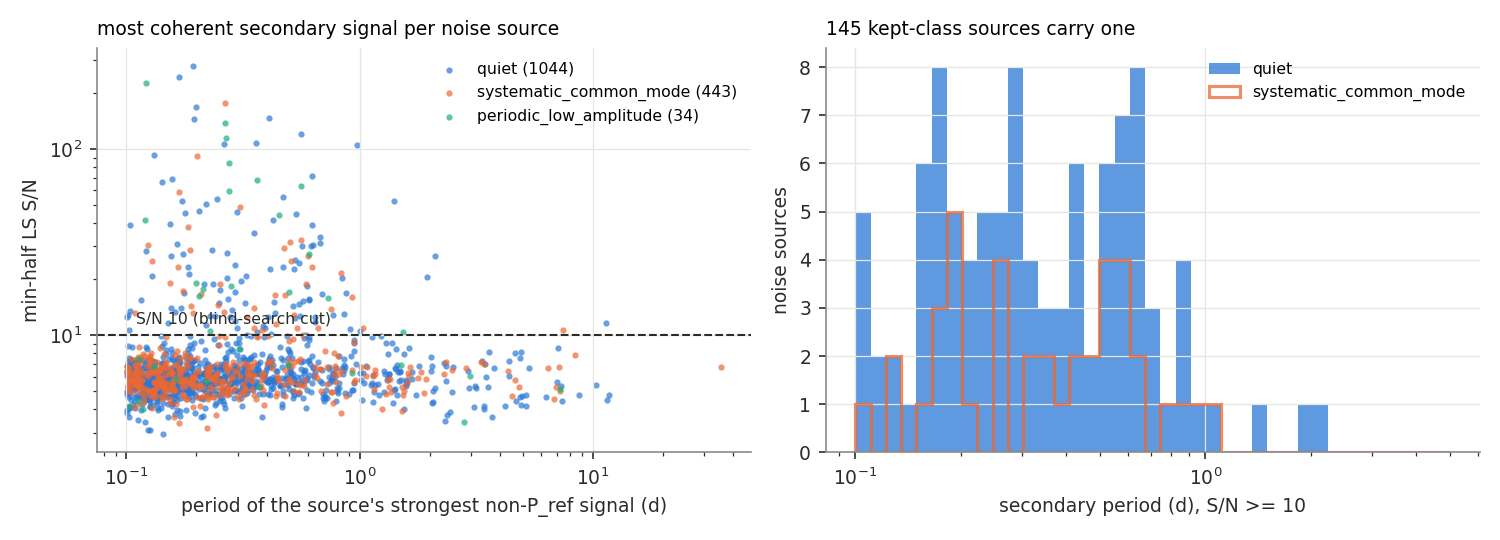

In [5]:
display(pd.DataFrame(S['population']))
print(json.load(open('data/secondary_file_counts.json')))
F.fig_population(); display(Image('figures/secondary_population.png'))

## The lure across v1 loss categories

{'answered_alias': 0.25, 'answered_success': 0.0181, 'answered_wrong': 0.5312, 'declined_alias_cand_only': 0.0517, 'declined_correct_cand_not_top1': 0.0831, 'declined_top1_right': 0.0241, 'no_correct_cand_searchable': 0.0674, 'no_correct_cand_unsearchable': 0.0261}
[{'src_has_secondary': False, 'n': 3366, 'answered': 958, 'wrong': 32, 'success': 915, 'wrong_per_answered': 0.033402922755741124}, {'src_has_secondary': True, 'n': 332, 'answered': 94, 'wrong': 17, 'success': 74, 'wrong_per_answered': 0.18085106382978725}]


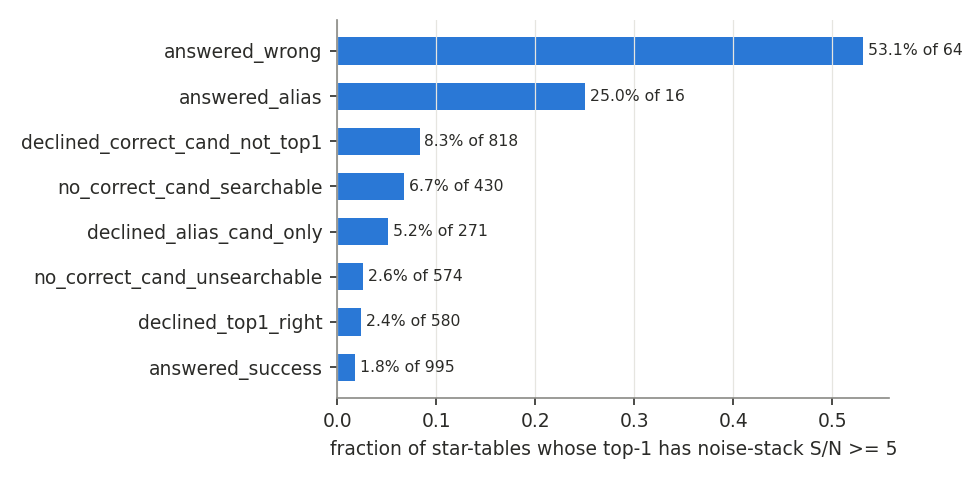

In [6]:
print(S['noise_coh_rate_by_category']); print(S['exposure_kept_classes'])
F.fig_categories(); display(Image('figures/noise_coherent_by_category.png'))